# P2 Notebook 4 — Interpretability (Saliency & Grad-CAM)

**Classes:** `cheetah`, `jaguar`, `leopard`, `ocelot`, `serval`

Notebook 3 found that all three Keras applications classify the test set at about 95%. This notebook asks **what the models
are actually looking at** when they do. It uses two methods from the provided `image_explainers.py`
(`U2-2_CNN-8_Explainability` §3):

- **Gradient saliency**, raw and SmoothGrad: which *pixels* would change the class score fastest if nudged
- **Grad-CAM**: which *regions* of the network's last feature maps carry the evidence for the class

It then hunts for **shortcuts**: evidence that a model separates the classes by something other than the cat. Notebook 2 left two
specific suspects:

1. **Habitat colour.** Jaguar and ocelot photos average greener and darker (rainforest, river), while cheetah and serval photos
   average warmer and yellower (savanna)
2. **Stock-photo watermarks and banners**, visible in every class's mean image, especially a band along the bottom edge

A picture can only suggest a shortcut, so each suspect is also tested with an **ablation**: part of every test image is greyed out,
and the change in accuracy is measured (`U2-2_CNN-9_FairnessAudit` §8).

## This notebook covers

1. Setup: test set, label mapping, and the three joined models
2. Both methods running on one image
3. Where to point them: correct predictions, misclassifications, and one image across all three models
4. The shortcut hunt: average Grad-CAM maps and occlusion ablations
5. Discussion

In [1]:
import gc
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras.applications import MobileNetV2, ResNet50, EfficientNetV2M

import image_explainers as xai       # provided module, in this same folder, imported unmodified

pd.set_option('display.max_columns', 100)
plt.style.use('dark_background')

PROJECT_DIR = Path.home() / 'P2_Images'                    # models/ lives here
PREP_DIR = Path.home() / 'MSDS565_data' / 'P2_prepared'    # Notebook 2's test set
MODELS_DIR = PROJECT_DIR / 'models'

SEED = 42
np.random.seed(SEED)          # SmoothGrad draws its noise from NumPy's global generator
keras.utils.set_random_seed(SEED)

## 1. Setup

### 1.1 Test set and label mapping

Notebook 2's test set is used exactly as it was saved: 355 images, centre-cropped to 224×224, raw `uint8` pixels from 0 to 255.
They are passed to `image_explainers` in that form, because its functions apply each application's own `preprocess_input`
themselves. The class names come from the `label_map.json` saved with the probes in Notebook 3, so the names line up with
the probes' outputs. `files_test.csv` gives each test image's source file, so any image shown below can be traced back to the
manifest.

In [2]:
X_test = np.load(PREP_DIR / 'X_test.npy')
y_test = np.load(PREP_DIR / 'y_test.npy')
files_test = pd.read_csv(PREP_DIR / 'files_test.csv')
label_map = json.loads((MODELS_DIR / 'label_map.json').read_text())
CLASSES = sorted(label_map, key=label_map.get)

assert len(X_test) == len(y_test) == len(files_test)
assert (files_test['label'].map(label_map) == y_test).all()
print(f'X_test {X_test.shape} {X_test.dtype}, values {X_test.min()}–{X_test.max()} | classes {CLASSES}')

X_test (355, 224, 224, 3) uint8, values 0–255 | classes ['cheetah', 'jaguar', 'leopard', 'ocelot', 'serval']


### 1.2 Rebuilding and joining the models

Each Keras application is rebuilt with **exactly** the arguments Notebook 3 used, its probe is loaded from `models/`, and the two are
joined into one model with `keras.Sequential([keras.Input(...), keras_app, probe])`, as in `U2-2_CNN-6_TransferLearning` §5. The
joined model takes a preprocessed image and returns the five class probabilities.

**A check that the rebuild is exact:** the joined models' test accuracy should reproduce Notebook 3's figures (94.4%, 94.9% and
94.9%). A mismatch would mean a different application, different weights or different preprocessing, and every map below
would then explain a different model from the one Notebook 3 evaluated. For this batch check, each image is given its
application's `preprocess_input`, found with `xai.find_preprocess_input`, so it is the same function the explainers use.

In [3]:
APPS = {
    'mobilenetv2': ('MobileNetV2', MobileNetV2),
    'resnet50': ('ResNet50', ResNet50),
    'effnetv2m': ('EfficientNetV2M', EfficientNetV2M),
}
MODELS, TITLES = {}, {}
for key, (title, build) in APPS.items():
    keras_app = build(include_top=False, weights='imagenet', pooling='avg', input_shape=(224, 224, 3))
    probe = keras.models.load_model(MODELS_DIR / f'P2_N3_{key}.keras')
    MODELS[key] = keras.Sequential([keras.Input((224, 224, 3)), keras_app, probe], name=f'joined_{key}')
    TITLES[key] = title


def predict_batch(key, images, batch_size=32):
    # Class probabilities for many raw 0–255 images, using the application's own preprocess_input.
    preprocess = xai.find_preprocess_input(MODELS[key].layers[0])
    out = [np.asarray(MODELS[key].predict(preprocess(images[i:i + batch_size].astype('float32')), verbose=0))
           for i in range(0, len(images), batch_size)]
    return np.concatenate(out)


PROBS = {key: predict_batch(key, X_test) for key in MODELS}
PREDS = {key: p.argmax(axis=1) for key, p in PROBS.items()}
pd.DataFrame([{'model': TITLES[k], 'test accuracy': round((PREDS[k] == y_test).mean(), 3),
               'errors': int((PREDS[k] != y_test).sum())} for k in MODELS]).set_index('model')

,test accuracy,errors
model,,
MobileNetV2,0.944,20
ResNet50,0.949,18
EfficientNetV2M,0.949,18


## 2. Both methods running

The two methods answer different questions, so they look very different:

- **Saliency** is the gradient of the class's *logit* (its score before softmax) with respect to every input pixel. It is
  pixel-precise but computed from a single gradient, so it is famously speckled. **SmoothGrad** (`smooth=32`) averages that
  gradient over 32 noisy copies of the image. The noise averages out, and only the pixels the model responds to consistently survive
- **Grad-CAM** weights each channel of the application's last feature maps by how much it raises the class's logit, and keeps
  only the positive part, the evidence *for* the class. It is coarse by construction, because it lives at the resolution of those
  feature maps, upsampled to 224×224

**Grad-CAM resolution.** `image_explainers` takes the *last* layer inside each application that still outputs a 4-D feature
map. The cell below finds that layer by the same rule and reports its grid:

In [4]:
res = {}
for key, model in MODELS.items():
    app = model.layers[0]
    last = [l for l in app.layers if not isinstance(l, keras.layers.InputLayer) and len(l.output.shape) == 4][-1]
    h, w, c = last.output.shape[1:]
    res[TITLES[key]] = {'last feature-map layer': last.name, 'grid': f'{h}×{w}', 'channels': c,
                        'pixels per cell': f'{224 // h}×{224 // w}'}
pd.DataFrame(res).T

,last feature-map layer,grid,channels,pixels per cell
MobileNetV2,out_relu,7×7,1280,32×32
ResNet50,conv5_block3_out,7×7,2048,32×32
EfficientNetV2M,top_activation,7×7,1280,32×32


All three applications end on a **7×7 grid** at 224×224 input, because each one downsamples its input by a factor of 32. A Grad-CAM map from
any of them can therefore only say which of 49 cells, each 32×32 pixels, carried the evidence. That is enough to tell the cat from
the background, but not a spot from a rosette. Saliency works at full resolution and fills in that detail.

The first example is a correctly classified test image, chosen at random with seed 42, and shown with all three maps by `xai.explain`, using EfficientNetV2M,
the model with the fewest `jaguar` ↔ `leopard` errors in Notebook 3. It is used as the main model for sections 2 and 3, and all
three models are compared in 3.3 and section 4.

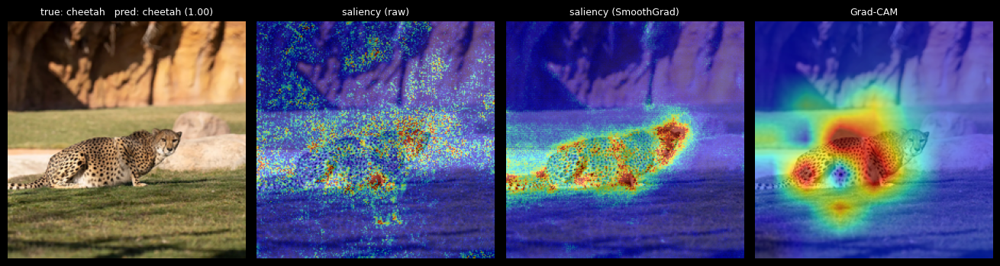

test image 32: cheetah/cheetah_0199.jpg


In [5]:
MAIN = 'effnetv2m'
correct = np.where(PREDS[MAIN] == y_test)[0]
wrong = np.where(PREDS[MAIN] != y_test)[0]
rng = np.random.default_rng(SEED)          # every image chosen in sections 2–3 comes from this generator

first = rng.choice(correct)
xai.explain(MODELS[MAIN], X_test[first], CLASSES, true_label=y_test[first])
print(f"test image {first}: {files_test.loc[first, 'label']}/{files_test.loc[first, 'filename']}")

**Reading the first example (a cheetah lying on grass, predicted cheetah at 1.00).** Grad-CAM puts the evidence on the cheetah's
body and head, and SmoothGrad traces the same animal, with its strongest response along the spotted flank and the face.
**Raw saliency against SmoothGrad:** the raw single-gradient map is speckled across the whole frame, grass and rock included,
with only a faint concentration on the cat. SmoothGrad, averaged over 32 noisy copies, removes that speckle and leaves the cat's
outline and spots. The raw map is not wrong, but one gradient is a noisy local measurement. Pixels that matter only by chance
for this exact image light up as brightly as pixels that matter consistently. This pattern repeats in every example below, so
SmoothGrad is the saliency map to read, and the raw map shows why it is needed.

## 3. Where to point them

### 3.1 Three correct predictions, three classes

One correctly classified test image each from three different classes, chosen at random with seed 42 from the images
EfficientNetV2M got right. Each row shows the image and its three maps for the predicted class.

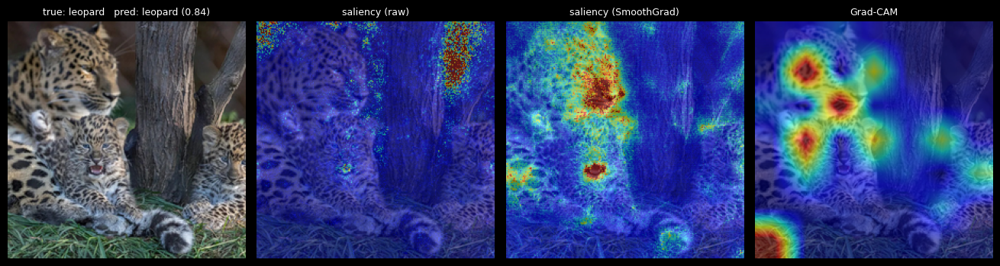

test image 150: leopard/leopard_0047.jpg


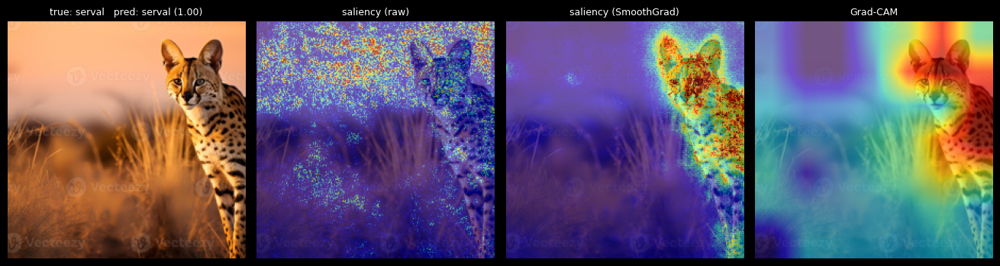

test image 334: serval/serval_0283.jpg


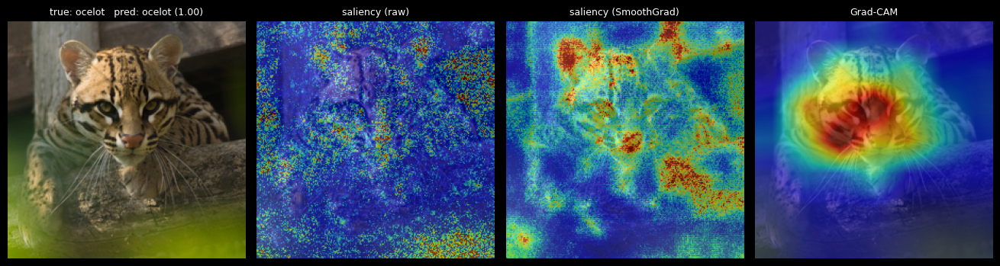

test image 228: ocelot/ocelot_0103.jpg


In [6]:
correct_classes = rng.choice(len(CLASSES), size=3, replace=False)
correct_picks = [rng.choice(correct[y_test[correct] == c]) for c in correct_classes]

for i in correct_picks:
    xai.explain(MODELS[MAIN], X_test[i], CLASSES, true_label=y_test[i])
    print(f"test image {i}: {files_test.loc[i, 'label']}/{files_test.loc[i, 'filename']}")

**What the correct predictions look at.** All three are decided by the animal:

- **Leopard with cubs (0.84):** Grad-CAM puts separate hot spots on the faces of the adult and both cubs, and SmoothGrad on the
  adult's head and a cub's face. The model finds every cat in the frame, not just the largest one
- **Serval in grass (1.00):** Grad-CAM covers the serval's head and its large ears, the serval's most distinctive feature.
  SmoothGrad outlines the whole animal. The faint "Vecteezy" watermarks scattered over the image get no evidence from either
  method. Raw saliency is busiest on the blurred sky, a clear case of the speckle described above
- **Ocelot (1.00):** Grad-CAM is centred on the face and its cheek stripes, the ocelot's signature marking, and SmoothGrad picks
  out the stripes and spots on the face and shoulder

One feature recurs: the leopard's Grad-CAM also has a **hot spot in the bottom-left corner**, where there is only grass. Section
4.1 shows the same spot in the average map for `jaguar` and `leopard`.

### 3.2 Three misclassified images

Misclassified images are the informative ones: was the model looking at the wrong object, at the background, or at something
we cannot identify? Three of EfficientNetV2M's errors are shown, chosen to cover different confusions where possible:
`jaguar` ↔ `leopard`, the pair Notebook 1 predicted, then the next most frequent confusions.

Each image is first shown with `xai.explain`, which maps the evidence for the **predicted** (wrong) class. A second figure then sets the
Grad-CAM for the predicted class beside the Grad-CAM for the **true** class (`class_index=`). That shows whether the
model saw the right animal and weighed it wrongly, or never looked at it.

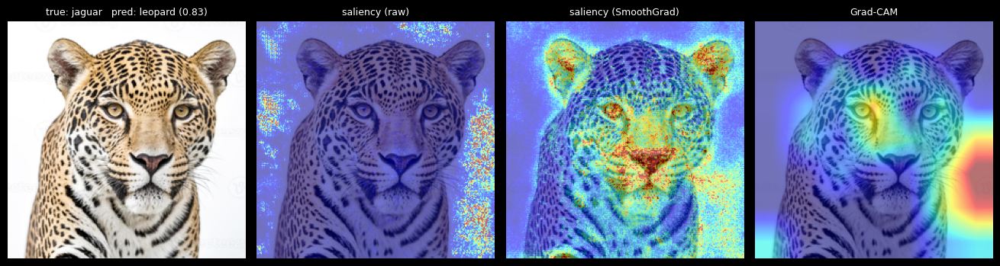

test image 111: jaguar/jaguar_0169.jpg


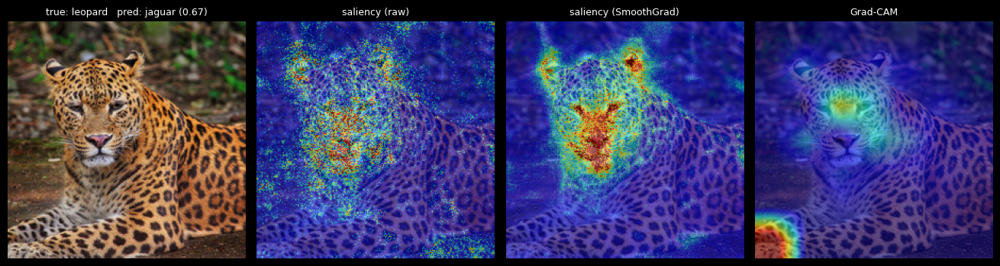

test image 154: leopard/leopard_0073.jpg


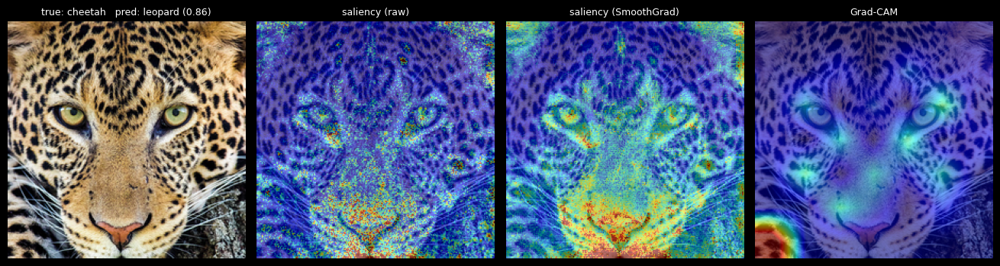

test image 6: cheetah/cheetah_0049.jpg


In [7]:
pairs = pd.Series([(CLASSES[y_test[i]], CLASSES[PREDS[MAIN][i]]) for i in wrong], index=wrong)
order = sorted(pairs.unique(), key=lambda p: (set(p) != {'jaguar', 'leopard'}, -(pairs == p).sum()))
wrong_picks = []
for p in order:                                   # one image per confusion type, most informative first
    wrong_picks.append(pairs[pairs == p].index[0])
    if len(wrong_picks) == 3:
        break
for i in wrong:                                   # fewer than three confusion types: fill from the rest
    if len(wrong_picks) == 3:
        break
    if i not in wrong_picks:
        wrong_picks.append(i)

for i in wrong_picks:
    xai.explain(MODELS[MAIN], X_test[i], CLASSES, true_label=y_test[i])
    print(f"test image {i}: {files_test.loc[i, 'label']}/{files_test.loc[i, 'filename']}")

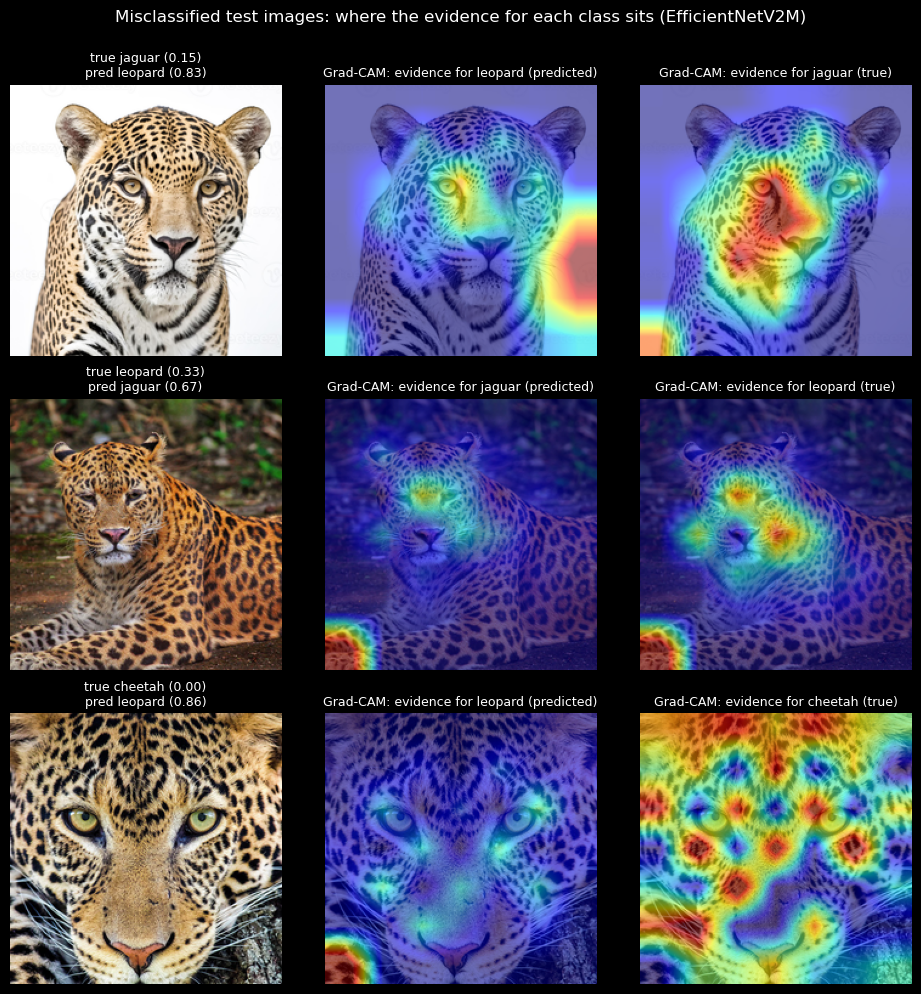

In [8]:
fig, axes = plt.subplots(len(wrong_picks), 3, figsize=(9.6, 3.3 * len(wrong_picks)))
for row, i in enumerate(wrong_picks):
    img, true, pred = X_test[i], int(y_test[i]), int(PREDS[MAIN][i])
    probs = PROBS[MAIN][i]
    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f'true {CLASSES[true]} ({probs[true]:.2f})\npred {CLASSES[pred]} ({probs[pred]:.2f})', fontsize=9)
    axes[row, 1].imshow(xai.overlay(img, xai.grad_cam(MODELS[MAIN], img, class_index=pred)))
    axes[row, 1].set_title(f'Grad-CAM: evidence for {CLASSES[pred]} (predicted)', fontsize=9)
    axes[row, 2].imshow(xai.overlay(img, xai.grad_cam(MODELS[MAIN], img, class_index=true)))
    axes[row, 2].set_title(f'Grad-CAM: evidence for {CLASSES[true]} (true)', fontsize=9)
    for ax in axes[row]:
        ax.axis('off')
plt.suptitle('Misclassified test images: where the evidence for each class sits (EfficientNetV2M)', y=1.0)
plt.tight_layout()
plt.show()

**What the three errors show.** `U2-2_CNN-8_Explainability` gives the reading. If the evidence for the true class and the
predicted class sit on the same region, the model looked at the right thing and weighed it wrongly. If they sit in different places,
something else in the frame distracted it.

- **Jaguar called leopard (0.83):** a studio portrait on a plain white background. The evidence for *jaguar* (the true class)
  is on the face, around the eye and nose, but the evidence for *leopard* sits mostly on the **white background** at the right edge.
  The model was distracted. A studio-white background is one of the shortcut types the prompt names, and a few cut-out "product"
  portraits like this survived cleaning. Here the background pushed the decision toward leopard
- **Leopard called jaguar (0.67 against 0.33):** both maps sit on the face, the true class on the cheeks and muzzle and the
  predicted class on the forehead. The model looked at the right thing and weighed it wrongly. This leopard is heavy-set, with large
  rosettes, and is genuinely jaguar-like, so this is an honest error on the hardest pair
- **"Cheetah" called leopard (0.86):** looking at the image, **the label is wrong**. It is a leopard's face, with rosettes,
  no tear marks and a broad muzzle. It was filed under `cheetah` by the search results and slipped through hand cleaning. The model is
  right and the label is not. So at least one of EfficientNetV2M's 18 test "errors" is a labelling error, and its true accuracy is slightly
  higher than reported

The bottom-left corner spot appears again here, in both leopard cases and in the evidence for *leopard* on the mislabelled face.

### 3.3 The same image across all three Keras applications

One test image that **all three** models classify correctly (other than the section 2 example), chosen at random with seed 42, shown with all three maps from each model,
smallest to largest. The question is whether the large model **localises** the cat better than the small one, or only scores
higher.

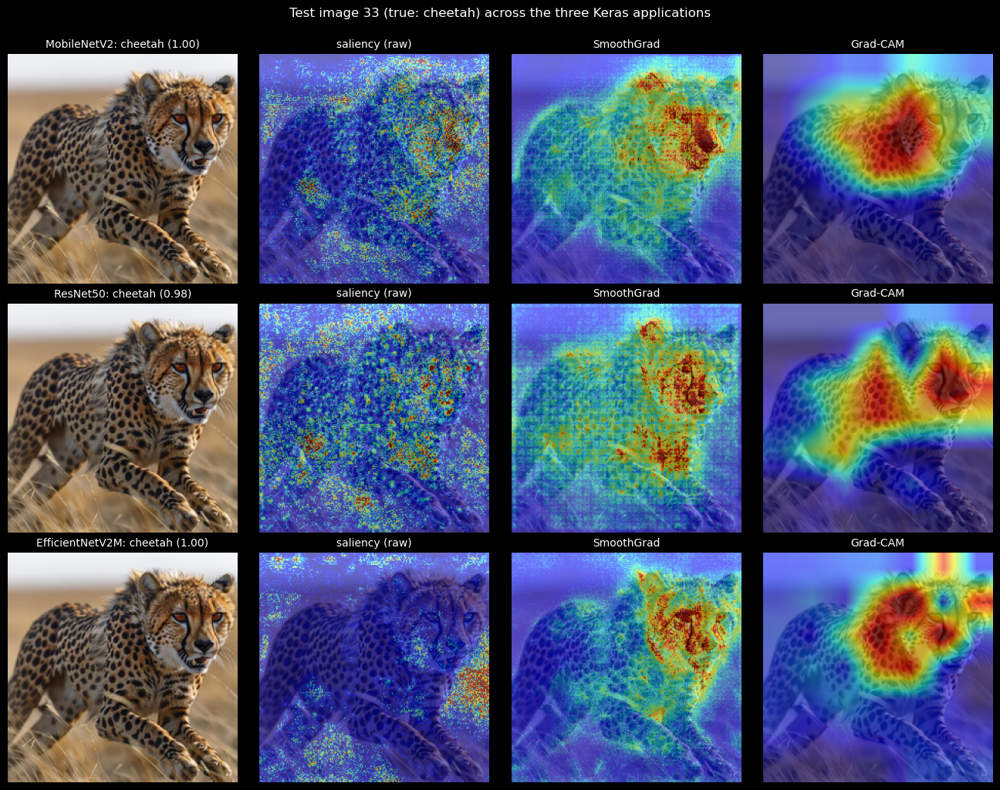

test image 33: cheetah/cheetah_0200.jpg


In [9]:
all_right = np.where((PREDS['mobilenetv2'] == y_test) & (PREDS['resnet50'] == y_test) & (PREDS['effnetv2m'] == y_test))[0]
shared = rng.choice(all_right[all_right != first])
img = X_test[shared]

fig, axes = plt.subplots(3, 4, figsize=(13.2, 10.2))
for row, key in enumerate(MODELS):
    probs = xai.predict_proba(MODELS[key], img)
    pred = int(np.argmax(probs))
    maps = [('saliency (raw)', xai.saliency(MODELS[key], img, class_index=pred)),
            ('SmoothGrad', xai.saliency(MODELS[key], img, smooth=32, class_index=pred)),
            ('Grad-CAM', xai.grad_cam(MODELS[key], img, class_index=pred))]
    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f'{TITLES[key]}: {CLASSES[pred]} ({probs[pred]:.2f})', fontsize=10)
    for col, (name, heat) in enumerate(maps, start=1):
        axes[row, col].imshow(xai.overlay(img, heat))
        axes[row, col].set_title(name, fontsize=10)
    for ax in axes[row]:
        ax.axis('off')
plt.suptitle(f"Test image {shared} (true: {CLASSES[y_test[shared]]}) across the three Keras applications", y=1.0)
plt.tight_layout()
plt.show()
print(f"test image {shared}: {files_test.loc[shared, 'label']}/{files_test.loc[shared, 'filename']}")

**One cheetah, three models.** All three classify it correctly and almost certainly (0.98–1.00), and all three find the cheetah,
but they localise it differently:

- **MobileNetV2:** Grad-CAM is one compact blob on the head and neck
- **ResNet50:** Grad-CAM spreads in a broad band across the back, shoulders and face, and reaches the right-hand edge of the frame
- **EfficientNetV2M:** Grad-CAM forms a tight ring around the head and shoulders, the most focused of the three

SmoothGrad agrees across all three: the strongest response is on the face, particularly the eye, the tear mark and the muzzle, with
the spotted body behind. Raw saliency is speckled for all three. For EfficientNetV2M it is brightest on the grass in the bottom-right
corner, where neither of its other maps puts any evidence.

**Does the large model localise better, or only score higher?** Somewhat better: its Grad-CAM is the tightest on the animal, and
ResNet50's spills into the background. But the difference is in focus, not in *what* is found. All three models locate the
head and coat, and all three are near-certain on this image. Section 4.2 measures the same question across the whole test set.

## 4. Shortcut hunt

Single images can be cherry-picked, so this section looks at the **whole test set**, in two ways:

- **4.1 Average Grad-CAM per class**, for EfficientNetV2M, the main model. Grad-CAM on every test image is the most
  memory-hungry step in the notebook, so it is run for one model; the ablations in 4.2 cover all three. If the model consistently
  relies on the bottom banner, its Grad-CAM averaged over a class will light up the bottom edge. Reliance on the cat should instead give a broad blob, roughly where cats sit in the frame. The
  share of all Grad-CAM evidence that falls in the **bottom band** (the bottom 12% of rows, where the banners in Notebook 2's mean
  images sit) is compared with that band's share of the image area. A model indifferent to the band puts about 12% of its evidence
  there
- **4.2 Ablations**, for all three models. Part of every test image is greyed out, and accuracy is measured again. Unlike a
  picture, this *measures* how much a model depends on that part

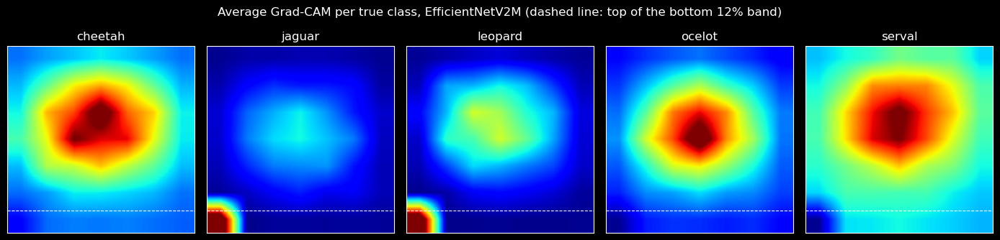

,% of Grad-CAM evidence in the bottom band (band = 12.1% of the image)
cheetah,6.4
jaguar,16.0
leopard,11.4
ocelot,5.1
serval,7.5
all classes,9.3


In [10]:
BAND = int(round(0.12 * 224))          # bottom 12% of rows = 27 rows
cams = []
for i in range(len(X_test)):
    cams.append(xai.grad_cam(MODELS[MAIN], X_test[i]))
    if i % 50 == 49:
        gc.collect()                   # release TensorFlow's per-call buffers as the loop runs
cams = np.stack(cams)

share = cams[:, -BAND:, :].sum(axis=(1, 2)) / (cams.sum(axis=(1, 2)) + 1e-8)
fig, axes = plt.subplots(1, len(CLASSES), figsize=(2.8 * len(CLASSES), 3.2))
for c, ax in enumerate(axes):
    ax.imshow(xai.norm(cams[y_test == c].mean(axis=0)), cmap='jet', vmin=0, vmax=1)
    ax.axhline(224 - BAND - 0.5, color='white', lw=0.8, ls='--')
    ax.set_title(CLASSES[c]); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle(f'Average Grad-CAM per true class, {TITLES[MAIN]} (dashed line: top of the bottom 12% band)', y=1.03)
plt.tight_layout()
plt.show()

band = pd.Series({c: 100 * share[y_test == k].mean() for k, c in enumerate(CLASSES)})
band['all classes'] = 100 * share.mean()
band.round(1).to_frame(f'% of Grad-CAM evidence in the bottom band (band = {100 * BAND / 224:.1f}% of the image)')

**Average maps: the cat, plus one corner.** For `cheetah`, `ocelot` and `serval`, the average Grad-CAM is a single broad blob in the
middle of the frame, where photographers put the animal. `jaguar` and `leopard` have weaker, more diffuse central blobs, because
their evidence is spread across varied positions, and both have a **sharp hot spot in the bottom-left corner**. `serval` shows a
faint one. That corner is where Alamy prints its logo in its bottom banner, which makes it a natural shortcut suspect.

Three pieces of evidence say it is **not** the logo:

1. **It appears where there is no logo.** The leopard cubs (3.1), the heavy-set leopard and the mislabelled leopard face (3.2)
   have no banner and no watermark in that corner, only grass or fur. They still show the spot
2. **The two methods disagree there.** In every one of those images, SmoothGrad saliency is cold in the bottom-left corner: changing
   those pixels barely changes the class score. If the model were reading the logo, the logo's pixels would matter. As
   `U2-2_CNN-8_Explainability` §4.4 puts it, disagreement is itself a diagnosis. Grad-CAM sees evidence at a *position* in the 7×7 feature
   grid that saliency cannot trace to *content*. That is the signature of a border effect inside the network (zero padding makes
   corner cells of the feature map behave differently), which the probe has come to weight for `jaguar` and `leopard`
3. **The ablation below finds no cost to removing that band** (4.2)

The bottom band holds **9.3% of all Grad-CAM evidence, below its 12.1% share of the image**, so overall the model pays the bottom
edge less attention than its size would predict. The exception is `jaguar`, at 16.0%. Its average map shows that this excess is the corner spot,
not a band across the bottom.

### 4.2 Ablations

Every test image is modified in one way, and each model's accuracy is measured again. Each region is filled with **mid-grey (128)**,
a flat neutral value that carries no colour or texture:

| Condition | What is greyed out | What it tests |
|---|---|---|
| **original** | nothing | the baseline, Notebook 3's accuracy |
| **bottom band greyed** | the bottom 12% of rows | **watermark and banner shortcut.** If accuracy drops, the models were using the band |
| **top band greyed** | the top 12% of rows | the **control** for the row above: the same amount of image removed somewhere banners do not sit. The bottom-band drop only counts as a shortcut if it clearly exceeds this one |
| **grayscale** | all colour (each image converted to gray, then back to 3 channels) | **reliance on colour**, both coat colour and habitat colour |
| **centre greyed (background only)** | the central 60%×60% box, where most cats sit | **habitat shortcut.** Chance is 20%. Accuracy well above chance from the background alone means the background carries class information the model can use |
| **border greyed (centre only)** | everything outside that central box | the reverse: how well the model does when most of the background is gone |

The central box is a rough stand-in for "the cat", because cats are not always centred and are often larger than the box. Some cat is
left in the background-only images, and some background in the centre-only ones. The two conditions are read together, as bounds,
not as exact measures.

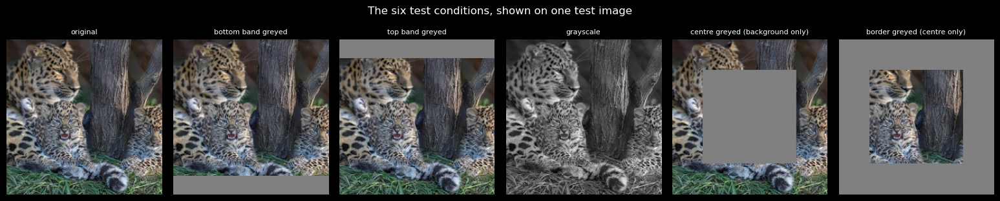

In [11]:
GREY = 128
c0, c1 = int(0.2 * 224), int(0.8 * 224)       # central 60% box


def ablate(images, condition):
    x = images.copy()
    if condition == 'bottom band greyed':
        x[:, -BAND:, :, :] = GREY
    elif condition == 'top band greyed':
        x[:, :BAND, :, :] = GREY
    elif condition == 'grayscale':
        gray = np.round(x.astype(np.float32) @ np.array([0.299, 0.587, 0.114], dtype=np.float32)).astype(np.uint8)
        x = np.repeat(gray[..., None], 3, axis=-1)
    elif condition == 'centre greyed (background only)':
        x[:, c0:c1, c0:c1, :] = GREY
    elif condition == 'border greyed (centre only)':
        inner = x[:, c0:c1, c0:c1, :].copy()
        x[:] = GREY
        x[:, c0:c1, c0:c1, :] = inner
    return x


CONDITIONS = ['original', 'bottom band greyed', 'top band greyed', 'grayscale',
              'centre greyed (background only)', 'border greyed (centre only)']

example = correct_picks[0]
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(2.6 * len(CONDITIONS), 3.0))
for ax, cond in zip(axes, CONDITIONS):
    ax.imshow(ablate(X_test[example:example + 1], cond)[0])
    ax.set_title(cond, fontsize=8)
    ax.axis('off')
plt.suptitle('The six test conditions, shown on one test image', y=1.02)
plt.tight_layout()
plt.show()

In [12]:
ablation = {}
ablation_preds = {}
for cond in CONDITIONS:
    x = X_test if cond == 'original' else ablate(X_test, cond)
    for key in MODELS:
        preds = PREDS[key] if cond == 'original' else predict_batch(key, x).argmax(axis=1)
        ablation_preds[(key, cond)] = preds
        ablation.setdefault(cond, {})[TITLES[key]] = (preds == y_test).mean()

acc = pd.DataFrame(ablation).T.rename_axis('test accuracy')
drop = (acc - acc.loc['original']).rename_axis('change vs original (points)') * 100
display(acc.round(3))
drop.round(1)

,MobileNetV2,ResNet50,EfficientNetV2M
test accuracy,,,
original,0.944,0.949,0.949
bottom band greyed,0.941,0.932,0.941
top band greyed,0.927,0.921,0.944
grayscale,0.811,0.885,0.896
centre greyed (background only),0.572,0.682,0.806
border greyed (centre only),0.817,0.834,0.887


,MobileNetV2,ResNet50,EfficientNetV2M
change vs original (points),,,
original,0.0,0.0,0.0
bottom band greyed,-0.3,-1.7,-0.8
top band greyed,-1.7,-2.8,-0.6
grayscale,-13.2,-6.5,-5.4
centre greyed (background only),-37.2,-26.8,-14.4
border greyed (centre only),-12.7,-11.5,-6.2


In [13]:
bg_only = pd.DataFrame({TITLES[k]: [(ablation_preds[(k, 'centre greyed (background only)')][y_test == c] == c).mean()
                                    for c in range(len(CLASSES))] for k in MODELS}, index=CLASSES)
bg_only.round(3).rename_axis('recall, background only')

,MobileNetV2,ResNet50,EfficientNetV2M
"recall, background only",,,
cheetah,0.387,0.547,0.667
jaguar,0.486,0.671,0.914
leopard,0.643,0.671,0.843
ocelot,0.529,0.586,0.700
serval,0.829,0.943,0.914


**Ablation results.** Each figure below is a change in test accuracy, in percentage points; on 355 test images, one image is
0.28 points.

| Condition | MobileNetV2 | ResNet50 | EfficientNetV2M | What it shows |
|---|---|---|---|---|
| bottom band greyed | −0.3 | −1.7 | −0.8 | **No watermark or banner shortcut.** Removing the band where the banners sit costs about as much as removing the top band, the control (−1.7, −2.8 and −0.6). For two of the three models it costs *less*. The banners are not what the models classify by |
| grayscale | −13.2 | −6.5 | −5.4 | **Colour helps, but is not the main cue.** Without any colour the models still score 81–90%, so shape and coat pattern carry most of the decision. MobileNetV2 depends on colour most |
| centre greyed (background only) | −37.2 | −26.8 | −14.4 | **The image's edges alone carry a lot of class information.** Accuracy stays at 57%, 68% and 81%, far above the 20% chance level |
| border greyed (centre only) | −12.7 | −11.5 | −6.2 | Removing the edges costs every model something, so the models use information there |

The background-only result needs a caveat, because the grey box does not remove the cat. Cats are often larger than the central 60%
box, and in the example figure an adult leopard's head and two cubs remain fully visible around it. So "background only" means
"the image's edges, which often still contain parts of the animal". The per-class table backs this reading: background-only recall is highest
for `serval` (0.83–0.94), the tallest, longest-legged cat, whose ears and legs most often extend past a central box. It is
also high for `jaguar` with EfficientNetV2M (0.91), where the rivers and dense green of Notebook 2's mean images make the
setting distinctive. Habitat therefore contributes, especially for jaguar, but these numbers cannot separate it cleanly from the cat
parts left in the frame. They set an **upper bound** on how much the models could rely on context.

**EfficientNetV2M is the most robust to every ablation.** It loses the least accuracy under every condition: 14 points from
background only against MobileNetV2's 37, and 5 from grayscale against 13. The large model has more redundant evidence spread across
the image. It does not need any one region or cue, which is a more useful advantage than its accuracy, identical to ResNet50's
on unmodified images.

## 5. Discussion

**Do the two methods agree?** Mostly. On every correctly classified image, **Grad-CAM and SmoothGrad point at the same thing,
the animal**: usually its face (eyes, tear marks, cheek stripes, the serval's ears), then the spotted body. Raw saliency is the odd one
out, speckled across background textures such as sky, grass and rock, which SmoothGrad averages away. Where the methods *disagree*, the
disagreement is informative:

- The **bottom-left corner**, hot in Grad-CAM and cold in SmoothGrad, is a positional effect inside the network, not a learned
  watermark: a location the model weights, with no content behind it
- On the **studio-white jaguar**, Grad-CAM's evidence for the wrong class sits on the empty background, and SmoothGrad stays on the face.
  The model saw the jaguar but let the background tip the decision

**Shortcuts found, and how big they are:**

| Suspect | Verdict |
|---|---|
| Stock-photo watermarks and banners | **Not used.** Greying the banner band costs no more than the control band. The corner hot spot in Grad-CAM is a position effect, not the logo |
| Habitat and background | **Used, partly.** The edges of the image alone give 57–81% accuracy. Some of that is cat parts left visible, but jaguar's distinctive settings contribute. Colour matters modestly (5–13 points) |
| Studio-white backgrounds | **Seen in one error.** A plain white background pushed a jaguar portrait to leopard. Such images are rare in the dataset |

**Would we deploy this model?** Not as a real-world identifier. As a classroom demonstration, yes: about 95% on held-out web photos,
with errors concentrated on the genuinely hard `jaguar` ↔ `leopard` pair and maps that mostly sit on the animal. Four things stand in
the way of real use:

1. **It has no way to say "none of these".** A softmax over five classes must pick one, so a house cat, a lion or a photo of a car
   will be confidently assigned to a spotted cat
2. **Some labels are wrong.** At least one test "error" is a mislabelled leopard, so the hand cleaning missed some. The true accuracy is a little
   higher than measured, but the training set also contains a few wrong labels
3. **Context leaks in.** The model can often classify from the edges of the image, which will not hold for photos taken in
   unusual settings (a jaguar in a dry zoo, a leopard on a white background)
4. **All the data is stock photography**, heavily watermarked and professionally framed. User photos from a phone will look different

**What to fix first: better cleaning.** Review every misclassified training and test image by eye, since the mislabelled leopard shows
these are where label errors surface, and remove the remaining cut-out studio portraits. That is quick, cheap, and fixes the
only problem found here that corrupts the measurement itself. **Second, more and more varied data**, especially `jaguar` and `leopard`
photos from outside stock sites, to reduce both the hard-pair errors and the background reliance. A different Keras application is
the *last* thing to change: Notebook 3 showed size buys almost nothing here, and this notebook showed the large model's real advantage is
robustness, not accuracy. For the Streamlit app, an honest addition would be a confidence threshold below which the app says
"not sure", rather than naming a class.